In [101]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
import torch
from torch import nn


# The physical problem

A rod with fixed, zero-temperature ends. In dimensionless variables,
$$
\frac{\partial u}{\partial t}
= \alpha \frac{\partial^2 u}{\partial x^2},
\qquad x \in [0,1], \quad t \in [0,1],
\qquad \alpha = 0.1.
$$

The initial and boundary conditions are

$$
u(x,0) = \sin(\pi x), \qquad
u(0,t) = u(1,t) = 0.
$$

### Analytical Solution

$$
\boxed{u(x,t) = \sin(\pi x)e^{-0.1\pi^2t}}
$$


### Four milestones:
1. Generate and verify an analytical reference.
2. Build a network $u_\theta(x,t)$ and compute its input derivatives.
3. Train it using temperature observations, the PDE, and initial and boundary conditions.
4. Evaluate its error at points withheld from training.


In [91]:
alpha = 0.1
def u_exact(x,t):
    return np.sin(np.pi*x)*np.exp(-alpha*np.pi**2*t)


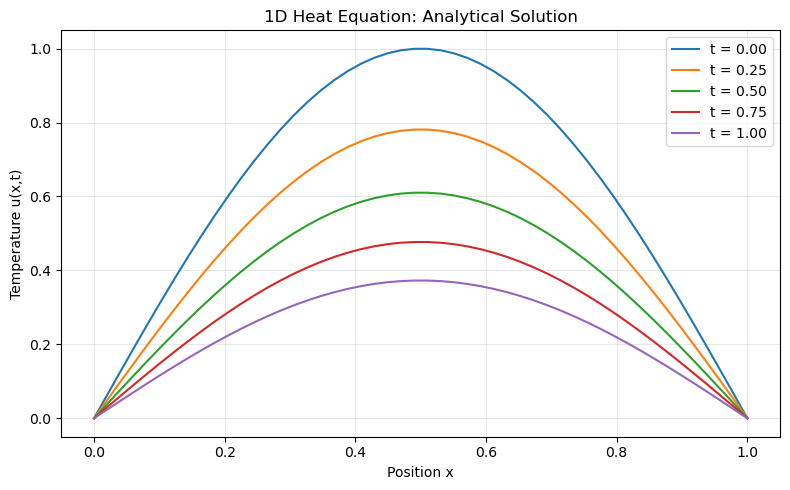

In [92]:
x = np.linspace(0, 1, 50)
times = [0.0, 0.25, 0.5, 0.75, 1.0]

plt.figure(figsize=(8,5))

for t in times:
    plt.plot(x, u_exact(x, t), label=f"t = {t:.2f}")
    
plt.xlabel("Position x")
plt.ylabel("Temperature u(x,t)")
plt.title("1D Heat Equation: Analytical Solution")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [103]:
# rng = np.random.default_rng(42)

x_obs = rng.uniform(0, 1, size=(128, 1))
t_obs = rng.uniform(0, 1, size=(128, 1))

xt_obs = np.concatenate((x_obs, t_obs), axis=1)
u_obs = u_exact(x_obs, t_obs)

print(u_obs.shape)  # (128, 1)

print(xt_obs.shape)  # should be (128, 2)
print(xt_obs[:5])

(128, 1)
(128, 2)
[[0.77395605 0.10340297]
 [0.43887844 0.58764457]
 [0.85859792 0.17059297]
 [0.69736803 0.92512012]
 [0.09417735 0.58106114]]


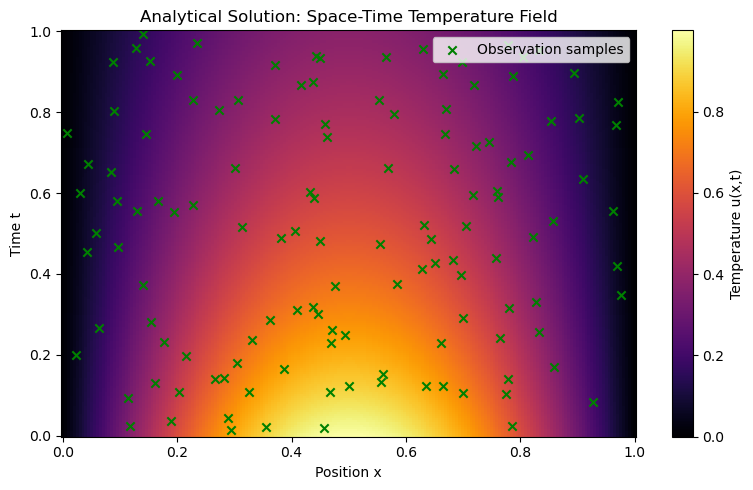

In [94]:
x = np.linspace(0, 1, 200)
t = np.linspace(0,1,200)

X, T = np.meshgrid(x,t)

U = u_exact(X, T)


plt.figure(figsize=(8,5))
plt.pcolormesh(X, T, U, shading="auto", cmap="inferno")

plt.colorbar(label="Temperature u(x,t)")

plt.scatter(x_obs, t_obs, c="green", marker="x", label="Observation samples")
plt.legend(loc="upper right")
plt.xlabel("Position x")
plt.ylabel("Time t")
plt.title("Analytical Solution: Space-Time Temperature Field")
plt.tight_layout()
plt.show()

In [95]:
## Sampling initial conditions
# rng = np.random.default_rng(42)

x_init = rng.uniform(0, 1, size=(64, 1))
t_init = np.zeros((64, 1)) #rng.uniform(0, 1, size=(128, 1))
u_init = np.sin(np.pi*x_init)

xt_init = np.concatenate((x_init, t_init), axis=1)
print(xt_init.shape)  # should be (64, 2)
print("(x_init, t_init) =", xt_init[:5])
print("u_init=", u_init[:5])

(64, 2)
(x_init, t_init) = [[0.81656876 0.        ]
 [0.10527808 0.        ]
 [0.06655886 0.        ]
 [0.59443366 0.        ]
 [0.14617324 0.        ]]
u_init= [[0.54489696]
 [0.32474381]
 [0.20758039]
 [0.95631466]
 [0.44324617]]


In [96]:
## Sampling left boundary conditions
# rng = np.random.default_rng(42)

x_leftBC = np.zeros((64,1)) # rng.uniform(0, 1, size=(64, 1))
t_leftBC = rng.uniform(0, 1, size=(64, 1))
u_leftBC = np.zeros((64,1))

xt_leftBC = np.concatenate((x_leftBC, t_leftBC), axis=1)
print(xt_leftBC.shape)  # should be (64, 2)
print("(x_leftBC, t_leftBC) =", xt_leftBC[:5])
print("u_leftBC=", u_leftBC[:5])

(64, 2)
(x_leftBC, t_leftBC) = [[0.         0.91634802]
 [0.         0.48091043]
 [0.         0.32836121]
 [0.         0.53543479]
 [0.         0.84856049]]
u_leftBC= [[0.]
 [0.]
 [0.]
 [0.]
 [0.]]


In [97]:
## Sampling right boundary conditions


x_rightBC = np.ones((64,1)) # rng.uniform(0, 1, size=(64, 1))
t_rightBC = rng.uniform(0, 1, size=(64, 1))
u_rightBC = np.zeros((64,1))

xt_rightBC = np.concatenate((x_rightBC, t_rightBC), axis=1)
print(xt_rightBC.shape)  # should be (64, 2)
print("(x_rightBC, t_rightBC) =", xt_rightBC[:5])
print("u_rightBC=", u_rightBC[:5])

(64, 2)
(x_rightBC, t_rightBC) = [[1.         0.37635947]
 [1.         0.98663154]
 [1.         0.71776024]
 [1.         0.95119466]
 [1.         0.11847858]]
u_rightBC= [[0.]
 [0.]
 [0.]
 [0.]
 [0.]]


In [98]:
## Sampling PDE collocation points


x_PDE = rng.uniform(0, 1, size=(1024, 1))
t_PDE = rng.uniform(0, 1, size=(1024, 1))


xt_PDE = np.concatenate((x_PDE, t_PDE), axis=1)
print(xt_PDE.shape)  # should be (64, 2)
print("(x_PDE, t_PDE) =", xt_PDE[:5])

(1024, 2)
(x_PDE, t_PDE) = [[0.05450031 0.10731236]
 [0.61630897 0.4976477 ]
 [0.04235055 0.5195496 ]
 [0.88414571 0.50819291]
 [0.70957829 0.43666749]]


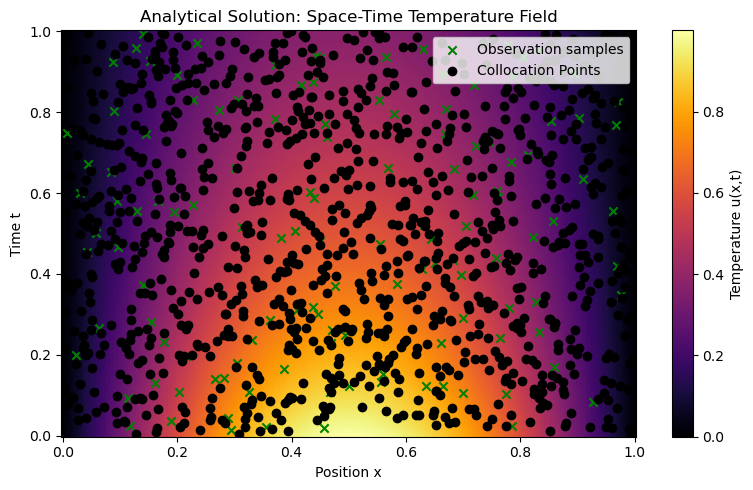

In [99]:
x = np.linspace(0, 1, 200)
t = np.linspace(0,1,200)

X, T = np.meshgrid(x,t)

U = u_exact(X, T)


plt.figure(figsize=(8,5))
plt.pcolormesh(X, T, U, shading="auto", cmap="inferno")

plt.colorbar(label="Temperature u(x,t)")

plt.scatter(x_obs, t_obs, c="green", marker="x", label="Observation samples")
plt.scatter(x_PDE, t_PDE, c="black", marker="o", label="Collocation Points")
plt.legend(loc="upper right")
plt.xlabel("Position x")
plt.ylabel("Time t")
plt.title("Analytical Solution: Space-Time Temperature Field")
plt.tight_layout()
plt.show()

#### At an observation point, the error is

$$
\underbrace{u_\theta(x_i,t_i)}_{\text{network prediction}}
-
\underbrace{u_{\text{exact}}(x_i,t_i)}_{\text{known temperature}}
$$

#### Error at a Collocation Point


$$
\underbrace{
u_{\theta,t}(x_j,t_j)
-
0.1u_{\theta,xx}(x_j,t_j)
}_{\text{PDE residual}}
$$

In [108]:
#Converting to tensors

xt_obs_t = torch.tensor(xt_obs, dtype=torch.float32)
u_obs_t = torch.tensor(u_obs, dtype=torch.float32)

xt_PDE_t = torch.tensor(xt_PDE, dtype=torch.float32)
xt_PDE_t.requires_grad_(True)

xt_leftBC_t = torch.tensor(xt_leftBC, dtype=torch.float32)
xt_rightBC_t = torch.tensor(xt_rightBC, dtype=torch.float32)
xt_init_t = torch.tensor(xt_init, dtype=torch.float32)

u_leftBC_t = torch.tensor(u_leftBC, dtype=torch.float32)
u_rightBC_t = torch.tensor(u_rightBC, dtype=torch.float32)
u_init_t = torch.tensor(u_init, dtype=torch.float32)


In [115]:
torch.manual_seed(42)

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,1)
        )
        
    def forward(self, xt):
            return self.network(xt)

In [119]:
model = PINN()

test_input = xt_obs_t[:7]
test_output = model(test_input)

print(test_input.shape)   

print(test_output.shape) 

assert test_output.shape == (7, 1)


torch.Size([7, 2])
torch.Size([7, 1])
